| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../15_SCIENTIFIC_MACHINE_LEARNING/15_4_Reduced_Order_Modeling.ipynb) | [⏩](../15_SCIENTIFIC_MACHINE_LEARNING/15_6_Differentiable_Physics.ipynb) |

# 15.5 Neural ODEs: aprender el campo vectorial de una dinámica

Una Neural ODE representa la **derivada temporal** mediante una red. Para predecir estados, integra esa derivada con un solver. Entrenaremos un campo escalar a partir de trayectorias, diferenciando a través de un RK4 escrito en PyTorch, y comprobaremos trayectorias con condiciones iniciales nuevas.

**Objetivos:** conectar ResNets y ODE; separar campo y trayectoria; entender el gradiente a través del solver; estudiar paso temporal, estabilidad y generalización. **Prerrequisitos:** capítulos 5, 7 y 12. **Librerías:** NumPy, SciPy, Matplotlib y PyTorch. No necesitas `torchdiffeq` ni GPU.

## 1. Del bloque residual al tiempo continuo

Un bloque residual puede escribirse $z_{n+1}=z_n+h f_\theta(z_n,t_n)$. Esta es la forma de un paso Euler para

$$\boxed{\frac{dz}{dt}=f_\theta(z,t),\qquad z(t_0)=z_0.}$$

El campo $f_\theta$ determina pendientes; el solver determina cómo aproximar la trayectoria. El número de evaluaciones del campo depende del método y su resolución temporal. Cambiar el solver puede cambiar las predicciones y los gradientes si el error de integración no es despreciable.

Una red que recibe $t$ y produce directamente $z_\theta(t)$ no es esta construcción. Aquí el estado futuro se obtiene integrando un campo que recibe el estado actual. Si el sistema es autónomo, el campo no depende explícitamente del tiempo y puede evaluarse desde distintas condiciones iniciales.

## 2. Un sistema de referencia no lineal

Generaremos datos con

$$z'=-z-0.2z^3=-z(1+0.2z^2).$$

El equilibrio es cero. La función $V(z)=z^2/2$ tiene derivada

$$\dot V=zz'=-z^2-0.2z^4\leq0,$$

por lo que la dinámica disipa esa energía. Condiciones positivas decaen hacia cero y condiciones negativas aumentan hacia cero sin cruzarlo en la solución continua. El término cúbico cambia la tasa de decaimiento con la amplitud; una única exponencial no describe todas las condiciones iniciales.

Usaremos tres trayectorias para entrenamiento. La red no recibe etiquetas de derivadas: solo estados observados y condiciones iniciales. Conocer la ODE del generador nos permite evaluarla después sin usar su campo como objetivo supervisado.

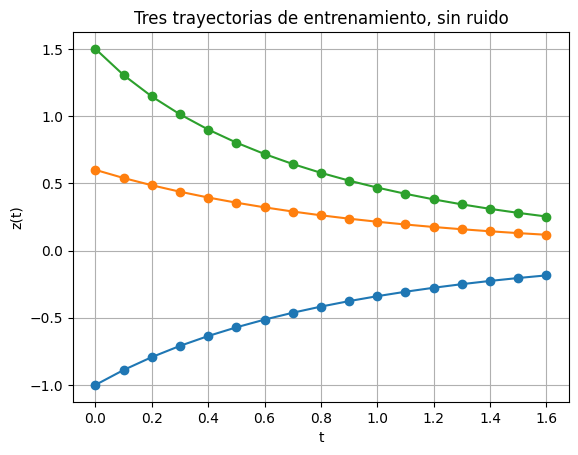

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import torch
from torch import nn
torch.manual_seed(155)
torch.set_num_threads(1)
torch.set_default_dtype(torch.float64)
f_real = lambda t,z: -z-0.2*z**3
ts_np = np.linspace(0, 1.6, 17)
z0_train = np.array([-1.0, 0.6, 1.5])
def referencia(z0, ts):
    sol = solve_ivp(f_real, (float(ts[0]),float(ts[-1])), [float(z0)],
                    t_eval=ts, rtol=1e-10, atol=1e-12)
    assert sol.success
    return sol.y[0]
Y_np = np.column_stack([referencia(z0, ts_np) for z0 in z0_train])
plt.plot(ts_np, Y_np, 'o-')
plt.xlabel('t'); plt.ylabel('z(t)'); plt.title('Tres trayectorias de entrenamiento, sin ruido')
plt.grid(); plt.show()
ts = torch.tensor(ts_np)
z0_t = torch.tensor(z0_train[:,None])
Y = torch.tensor(Y_np[:,:,None])  # [tiempo, trayectoria, variable]

## 3. Incorporar estabilidad en la parametrización

En lugar de un campo completamente libre, construiremos

$$f_\theta(z)=-z\operatorname{softplus}(N_\theta(z^2)).$$

`softplus` devuelve una tasa positiva. Para la ODE continua esto garantiza $zf_\theta(z)\leq0$, equilibrio en cero y simetría impar $f_\theta(-z)=-f_\theta(z)$. La arquitectura expresa una hipótesis física: disipación y simetría del sistema de referencia.

No puede representar campos con crecimiento sostenido o desplazamiento del equilibrio. Es adecuado para este experimento porque la hipótesis corresponde a la dinámica. Si esa física fuera incorrecta, la restricción introduciría sesgo.

La disipación continua tampoco garantiza que cualquier discretización sea estable para cualquier paso. Un Euler explícito demasiado grande puede aumentar amplitudes aunque el campo sea disipativo. Evaluaremos el paso temporal por separado.

In [2]:
class CampoDisipativo(nn.Module):
    def __init__(self):
        super().__init__()
        self.tasa = nn.Sequential(nn.Linear(1, 16), nn.Tanh(), nn.Linear(16, 1))
    def forward(self, z):
        return -z*torch.nn.functional.softplus(self.tasa(z.square()))

campo = CampoDisipativo()
def paso_rk4(f, z, h):
    k1 = f(z)
    k2 = f(z+0.5*h*k1)
    k3 = f(z+0.5*h*k2)
    k4 = f(z+h*k3)
    return z+h*(k1+2*k2+2*k3+k4)/6

def integrar(f, z0, tiempos, subpasos=2):
    # Se conservan tensores en el grafo: no usar numpy ni detach aquí.
    z = z0
    estados = [z]
    for i in range(len(tiempos)-1):
        h = (tiempos[i+1]-tiempos[i])/subpasos
        for _ in range(subpasos): z = paso_rk4(f, z, h)
        estados.append(z)
    return torch.stack(estados)

prueba = integrar(campo, z0_t, ts)
print('Forma [tiempo, trayectoria, variable]:', tuple(prueba.shape))

Forma [tiempo, trayectoria, variable]: (17, 3, 1)


## 4. Entrenar con error de trayectoria

El solver produce $z_\theta(t_i;z_0^{(j)})$. Minimizamos

$$\mathcal L(\theta)=\frac1{NK}\sum_{j=1}^N\sum_{i=1}^K
[z_\theta(t_i;z_0^{(j)})-y_i^{(j)}]^2.$$

Los parámetros influyen en cada paso y en todos los posteriores. Autograd deriva las operaciones del RK4 desplegado en el tiempo: este procedimiento se llama **diferenciar la discretización**. El gradiente corresponde a nuestro solver discreto, que aproxima el problema continuo.

Guardamos todas las operaciones necesarias para retropropagar, por lo que la memoria crece con el número de pasos. Este ejemplo **no implementa el método adjunto de memoria reducida** del artículo original. Hace visible el grafo y permite comprobarlo fácilmente en un sistema pequeño.

MSE final de entrenamiento: 4.149299957107824e-06


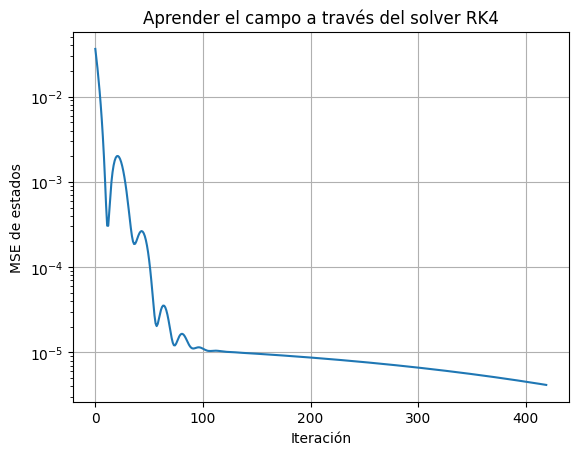

In [3]:
opt = torch.optim.Adam(campo.parameters(), lr=0.01)
hist = []
for _ in range(420):
    opt.zero_grad(set_to_none=True)
    pred = integrar(campo, z0_t, ts, subpasos=2)
    loss = ((pred-Y)**2).mean()
    loss.backward(); opt.step(); hist.append(loss.item())
plt.semilogy(hist)
plt.xlabel('Iteración'); plt.ylabel('MSE de estados')
plt.title('Aprender el campo a través del solver RK4'); plt.grid(); plt.show()
print('MSE final de entrenamiento:', hist[-1])

## 5. Comprobar nuevas condiciones iniciales

Una trayectoria reservada debe partir de una condición no usada al entrenar. Probamos $z_0=1.2$ y $z_0=-0.8$ hasta $t=3.2$. Estos estados iniciales están dentro del rango cubierto por las trayectorias de entrenamiento; el tiempo final supera el intervalo observado.

Como el campo es autónomo, predecir tiempos tardíos en esta dinámica estable lleva el estado hacia cero, una región ya cubierta. Es una extensión temporal favorable, no una prueba de generalización a estados de gran amplitud. La siguiente sección examina también el campo fuera del rango observado.

Usamos una malla más fina para integrar la red y `solve_ivp` de tolerancia estricta para la referencia. Así separamos mejor el error aprendido del error de RK4.

RMSE reservado: 0.001891959890541869


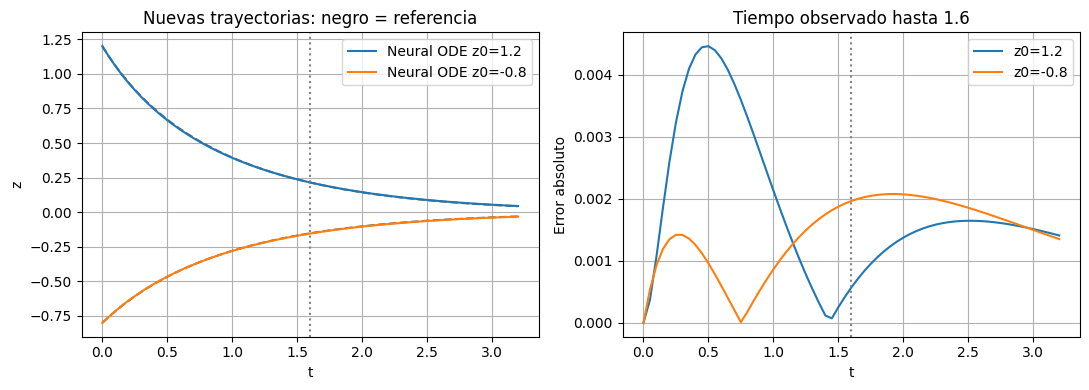

In [4]:
ts_test_np = np.linspace(0, 3.2, 65)
ts_test = torch.tensor(ts_test_np)
z0_test = np.array([1.2, -0.8])
ref_test = np.column_stack([referencia(z0, ts_test_np) for z0 in z0_test])
with torch.no_grad():
    pred_test = integrar(campo, torch.tensor(z0_test[:,None]), ts_test, subpasos=2).numpy()[:,:,0]
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for j,z0 in enumerate(z0_test):
    axes[0].plot(ts_test_np, ref_test[:,j], 'k--', alpha=0.6)
    axes[0].plot(ts_test_np, pred_test[:,j], label=f'Neural ODE z0={z0}')
    axes[1].plot(ts_test_np, np.abs(pred_test[:,j]-ref_test[:,j]), label=f'z0={z0}')
for ax in axes:
    ax.axvline(1.6, color='gray', linestyle=':'); ax.legend(); ax.grid()
axes[0].set(xlabel='t', ylabel='z', title='Nuevas trayectorias: negro = referencia')
axes[1].set(xlabel='t', ylabel='Error absoluto', title='Tiempo observado hasta 1.6')
plt.tight_layout(); plt.show()
rmse = np.sqrt(np.mean((pred_test-ref_test)**2))
print('RMSE reservado:', rmse)
assert np.isfinite(pred_test).all() and rmse < 0.03

## 6. Validar el campo, no solo sus trayectorias

Diferentes campos pueden producir trayectorias parecidas en un intervalo limitado. Las observaciones restringen principalmente los estados visitados. Dibujamos $f_\theta(z)$ junto al campo real para examinar las pendientes y la región sin datos.

La estructura disipativa puede seguir correcta fuera del entrenamiento y, sin embargo, la tasa estar equivocada. Conservar una propiedad cualitativa no equivale a acertar magnitudes. En problemas reales sin campo conocido, pueden comprobarse invariantes, velocidades observadas o experimentos independientes.

Máximo z*f(z), debe ser <=0: -0.0


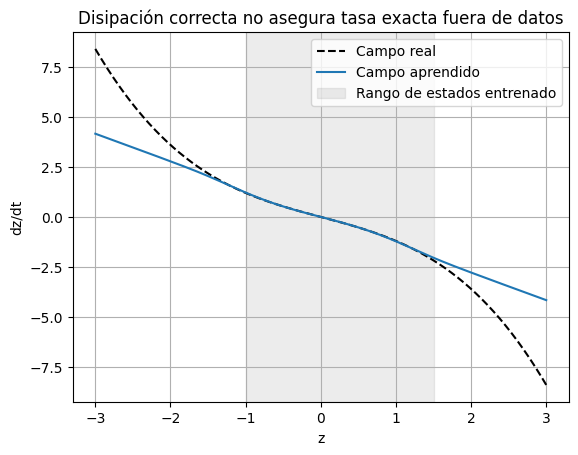

In [5]:
z_grid = np.linspace(-3, 3, 301)
with torch.no_grad(): f_pred = campo(torch.tensor(z_grid[:,None])).numpy().ravel()
plt.plot(z_grid, -z_grid-0.2*z_grid**3, 'k--', label='Campo real')
plt.plot(z_grid, f_pred, label='Campo aprendido')
plt.axvspan(-1.0, 1.5, color='gray', alpha=0.15, label='Rango de estados entrenado')
plt.xlabel('z'); plt.ylabel('dz/dt'); plt.title('Disipación correcta no asegura tasa exacta fuera de datos')
plt.legend(); plt.grid(); plt.show()
print('Máximo z*f(z), debe ser <=0:', np.max(z_grid*f_pred))

## 7. El paso temporal es parte de la aproximación

Con pesos fijos, refinamos la integración. Para una solución suave, RK4 tiene error global de orden cuatro en condiciones regulares. El error de aprendizaje permanece aunque el paso tienda a cero; las diferencias entre resoluciones revelan principalmente el error de integración del campo aprendido.

Un modelo entrenado con un solver muy impreciso puede compensar ese error modificando su campo. Si al cambiar de solver empeoran sus trayectorias, conviene investigar esa compensación antes de atribuir significado físico a los pesos.

Errores de integración: [1.56465154e-04 9.51913709e-06 5.67849909e-07 3.44882332e-08
 2.12227566e-09]


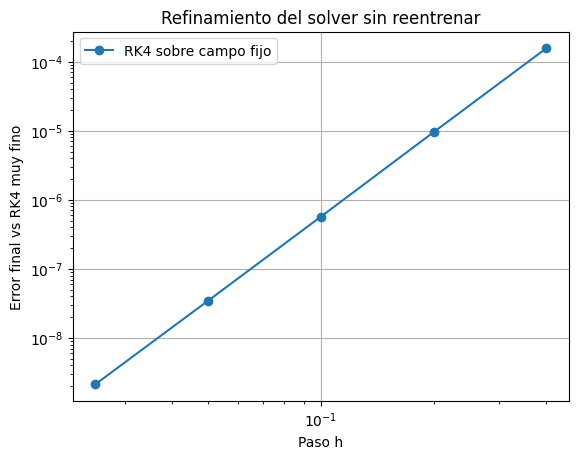

In [6]:
ts_fin = torch.tensor([0.0, 1.6])
z0_uno = torch.tensor([[1.2]])
subdivision = [4, 8, 16, 32, 64]
finales = []
with torch.no_grad():
    ref_integracion = integrar(campo, z0_uno, ts_fin, subpasos=512)[-1].item()
    for n_sub in subdivision:
        finales.append(integrar(campo, z0_uno, ts_fin, subpasos=n_sub)[-1].item())
err_integracion = np.abs(np.array(finales)-ref_integracion)
plt.loglog(1.6/np.array(subdivision), np.maximum(err_integracion,1e-16), 'o-', label='RK4 sobre campo fijo')
plt.xlabel('Paso h'); plt.ylabel('Error final vs RK4 muy fino')
plt.title('Refinamiento del solver sin reentrenar'); plt.grid(); plt.legend(); plt.show()
print('Errores de integración:', err_integracion)

## 8. Verificar un gradiente del programa

Autograd puede calcular un gradiente exacto de las operaciones diferenciables ejecutadas y aun así derivar un programa incorrecto. Un control útil compara una componente de $\partial_\theta z(T)$ con diferencias centrales, usando pesos y solver idénticos.

El paso de diferencias finitas debe ser suficientemente grande para evitar cancelación y pequeño para limitar truncamiento. No pretendemos sustituir autograd por diferencias finitas durante entrenamiento; hacemos una auditoría de una componente.

In [7]:
param = next(campo.parameters())
terminal = integrar(campo, z0_uno, ts_fin, subpasos=32)[-1,0,0]
grad = torch.autograd.grad(terminal, param)[0][0,0].item()
valor = param[0,0].item()
eps = 1e-5
with torch.no_grad():
    param[0,0] = valor+eps
    mas = integrar(campo, z0_uno, ts_fin, subpasos=32)[-1].item()
    param[0,0] = valor-eps
    menos = integrar(campo, z0_uno, ts_fin, subpasos=32)[-1].item()
    param[0,0] = valor
fd = (mas-menos)/(2*eps)
print('Gradiente autograd:', grad, '| diferencia central:', fd)
assert np.isclose(grad, fd, rtol=1e-3, atol=1e-6)

Gradiente autograd: 0.002023367174920666 | diferencia central: 0.0020233671765845784


## 9. Adjunto continuo y adjunto discreto

Para una pérdida terminal $\mathcal L=\ell(z(T))$, definimos $a(t)=\partial\mathcal L/\partial z(t)$. El adjunto continuo satisface

$$\dot a(t)=-[\partial_z f_\theta(z(t),t)]^Ta(t),\qquad a(T)=\nabla_z\ell,$$

y el gradiente formal incluye

$$\frac{d\mathcal L}{d\theta}=\int_0^T a(t)^T\partial_\theta f_\theta(z(t),t)\,dt.$$

Para pérdidas en tiempos intermedios, el adjunto tiene saltos con las derivadas de cada observación. Reconstruir estados e integrar hacia atrás requiere atención numérica; una dinámica estable hacia adelante puede ser inestable hacia atrás.

El adjunto discreto deriva el esquema realmente utilizado. Diferenciar primero la ecuación continua y después discretizar no coincide siempre con derivar una discretización fija. Nuestro RK4 desplegado usa la segunda estrategia a través de autograd y guarda su grafo. Para problemas grandes, checkpointing y solvers con adjunto ofrecen compromisos diferentes de memoria y precisión.

## 10. Identificabilidad, ruido y rigidez

Observar una única trayectoria escalar no determina necesariamente el campo en todo el espacio. En varias dimensiones, una trayectoria visita solo una parte pequeña del dominio. Nuevas condiciones iniciales o entradas externas aportan cobertura adicional.

Si observamos posiciones pero no velocidades, el estado físico puede requerir variables ocultas. Un modelo de primer orden sobre la posición sola no representa siempre un oscilador de segundo orden. Se puede ampliar el estado, pero la interpretación de las coordenadas latentes necesita cuidado.

Un campo aprendido rígido puede obligar a pasos muy pequeños y elevar el coste. Añadir regularización a derivadas o estructura física puede ayudar, pero debe verificarse sin eliminar dinámicas reales. Para comparar arquitecturas, registra evaluaciones del campo, error y método del solver.

| Inicio | Anterior | Siguiente |
| --- | --- | --- |
| [🏠](../README.md) | [⏪](../15_SCIENTIFIC_MACHINE_LEARNING/15_4_Reduced_Order_Modeling.ipynb) | [⏩](../15_SCIENTIFIC_MACHINE_LEARNING/15_6_Differentiable_Physics.ipynb) |